# 🧪 Notebook 11 — Adaptive VQE

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Advanced\
> **Estimated time:** 90 min\
> **Prerequisites:** VQE, commutators, UCC generators, Jordan–Wigner mapping, and Pauli measurement

---

## 📌 Overview

This notebook develops ADAPT-VQE algorithm, which grows a variational ansatz by selecting operators from a pool according to their energy gradients.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Build singlet and triplet excitation operator pools.
- Calculate gradients from Hamiltonian commutators.
- Select operators adaptively and optimize the growing ansatz using ADAPT-VQE algorithm.
- Diagnose particle and spin symmetry during convergence.

## 🔑 Key concepts

`ADAPT-VQE` · `operator pool` · `commutator` · `gradient screening` · `adaptive ansatz` · `spin sector`

## 🧩 Structure

1. Hamiltonian construction
2. Operator pools
3. Circuit construction
4. Gradient selection
5. Iterative optimization
6. Spin diagnostics

## 📚 Resources

- PySCF, OpenFermion, Qiskit, and SciPy documentation
- Previous notebook: `vqe.ipynb`

### ⏱️ Expected outcome

You will implement an adaptive VQE loop that selects relevant excitations and converges toward the singlet ground state.

# Adaptive VQE

ADAPT-VQE builds a variational circuit iteratively instead of choosing the complete ansatz in advance. At each iteration, an operator pool is screened using energy gradients, the most useful generator is appended, and the parameters of the growing circuit are reoptimized.

In [1]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner

In [2]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

In [3]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00 -2.16420228e-16]
 [-4.69718139e-16 -4.75068849e-01]]
[[[[ 6.74755927e-01  5.55111512e-17]
   [-8.32667268e-17  1.81210462e-01]]

  [[-8.32667268e-17  1.81210462e-01]
   [ 6.63711401e-01  3.60822483e-16]]]


 [[[ 5.55111512e-17  6.63711401e-01]
   [ 1.81210462e-01  5.27355937e-16]]

  [[ 1.81210462e-01  5.27355937e-16]
   [ 3.60822483e-16  6.97651504e-01]]]]
0.7151043390810812


In [4]:
from openfermion import InteractionOperator
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)

In [5]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nstates = 4
energy, ci = cisolver.kernel()
print("FCI energy:", energy)

FCI energy: [-1.13728383 -0.53077336 -0.16835243  0.48314267]


## Exact energies and spin labels

The FCI calculation provides a benchmark in the fixed electron-number sector. For each CI state, PySCF evaluates $\langle S^2\rangle$ and the code recovers $S$ from

$$S=\frac{-1+\sqrt{1+4\langle S^2\rangle}}{2},\qquad 2S+1=\text{spin multiplicity}. $$

The determinant amplitudes show which occupation patterns contribute most strongly to each exact state.

In [6]:
from pyscf import fci
from pyscf.fci import cistring, spin_op

cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nroots = 4

energies, ci = cisolver.kernel()

ncas = cisolver.norb
nelec = cisolver.nelec

na, nb = nelec

# Alpha and beta determinants
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (alpha beta alpha beta ...)."""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]

    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))

    return ''.join(inter)[::-1]


print('\namplitudes FCI')

tol_ampl = 0.01

for state, ci_state in enumerate(ci):

    # Compute S^2 and spin multiplicity
    s2, multiplicity = spin_op.spin_square(
        ci_state,
        ncas,
        nelec
    )

    # Recover S from S(S+1)
    spin = (-1 + (1 + 4 * s2)**0.5) / 2

    print(
        f'\nState {state}   '
        f'Energy = {energies[state]:+.10f}   '
        f'<S^2> = {s2:.6f}   '
        f'S = {spin:.1f}   '
        f'2S+1 = {multiplicity:.1f}'
    )

    for i, a in enumerate(alpha_det):
        for j, b in enumerate(beta_det):

            amp = ci_state[i, j]

            if amp**2 > tol_ampl:
                cfg = interleave_bits(a, b, ncas)
                print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f})")


amplitudes FCI

State 0   Energy = -1.1372838345   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
1100   +0.993647  (0.987334)
0011   -0.112544  (0.012666)

State 1   Energy = -0.5307733570   <S^2> = 2.000000   S = 1.0   2S+1 = 3.0
0110   +0.707107  (0.500000)
1001   -0.707107  (0.500000)

State 2   Energy = -0.1683524330   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
0110   -0.707107  (0.500000)
1001   -0.707107  (0.500000)

State 3   Energy = +0.4831426731   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
1100   +0.112544  (0.012666)
0011   +0.993647  (0.987334)


## Anti-Hermitian operator pools

For an excitation operator $A$, the generator used by a unitary ansatz is $\tau=A-A^\dagger$. It satisfies $\tau^\dagger=-\tau$, so $e^{\theta\tau}$ is unitary for real $\theta$. The pool contains single and double excitations; assigning `pool` to a different pool below changes the targeted spin sector.

In [7]:
from itertools import product
from openfermion import FermionOperator, hermitian_conjugated

#first singlet
pool = []
for i in range(2):
    for a in range(2, 4):
        op = FermionOperator(f'{a}^ {i}')
        pool.append(op - hermitian_conjugated(op))

for i in range(2):
    for j in range(i+1, 2):
        for a in range(2, 4):
            for b in range(a+1, 4):
                op = FermionOperator(f'{b}^ {a}^ {j} {i}')
                pool.append(op - hermitian_conjugated(op)) # antiHermitian

for op in pool:
    print(jordan_wigner(op))

-0.5j [X0 Z1 Y2] +
0.5j [Y0 Z1 X2]
-0.5j [X0 Z1 Z2 Y3] +
0.5j [Y0 Z1 Z2 X3]
-0.5j [X1 Y2] +
0.5j [Y1 X2]
-0.5j [X1 Z2 Y3] +
0.5j [Y1 Z2 X3]
0.125j [X0 X1 X2 Y3] +
0.125j [X0 X1 Y2 X3] +
-0.125j [X0 Y1 X2 X3] +
0.125j [X0 Y1 Y2 Y3] +
-0.125j [Y0 X1 X2 X3] +
0.125j [Y0 X1 Y2 Y3] +
-0.125j [Y0 Y1 X2 Y3] +
-0.125j [Y0 Y1 Y2 X3]


## Building the adaptive circuit

`get_circuit` starts from the Hartree-Fock occupation and appends one unitary for every selected generator. After the Jordan-Wigner transformation, each generator is a sum of Pauli strings, and each string is implemented with basis changes, parity CNOTs, and an RZ rotation. The ansatz therefore has the form

$$|\psi(\boldsymbol{\theta})\rangle=\prod_{k=1}^{m}e^{\theta_k\tau_k}|\Phi_0\rangle. $$

In [8]:
from openfermion import FermionOperator

# triplet (ms=0)
pool_2 = []
for i in [1, 2]:
    for a in range(4):
        op = FermionOperator(f'{a}^ {i}')
        pool_2.append(op - hermitian_conjugated(op)) # antiHermitian

for i in [1, 2]:
    for j in [1, 2]:
        if i >= j:
            continue
        for a in range(4):
            for b in range(a+1, 4):
                op = FermionOperator(f'{b}^ {a}^ {j} {i}') # antiHermitian
                pool_2.append(op - hermitian_conjugated(op))

for op in pool_2:
    print(jordan_wigner(op))

pool = pool_2

0.5j [X0 Y1] +
-0.5j [Y0 X1]
0
-0.5j [X1 Y2] +
0.5j [Y1 X2]
-0.5j [X1 Z2 Y3] +
0.5j [Y1 Z2 X3]
0.5j [X0 Z1 Y2] +
-0.5j [Y0 Z1 X2]
0.5j [X1 Y2] +
-0.5j [Y1 X2]
0
-0.5j [X2 Y3] +
0.5j [Y2 X3]
0.25j [X0 Z1 Y2] +
-0.25j [X0 Y2] +
-0.25j [Y0 Z1 X2] +
0.25j [Y0 X2]
-0.25j [X0 Y1] +
0.25j [X0 Y1 Z2] +
0.25j [Y0 X1] +
-0.25j [Y0 X1 Z2]
0.125j [X0 X1 X2 Y3] +
-0.125j [X0 X1 Y2 X3] +
-0.125j [X0 Y1 X2 X3] +
-0.125j [X0 Y1 Y2 Y3] +
0.125j [Y0 X1 X2 X3] +
0.125j [Y0 X1 Y2 Y3] +
0.125j [Y0 Y1 X2 Y3] +
-0.125j [Y0 Y1 Y2 X3]
0
-0.25j [Z1 X2 Y3] +
0.25j [Z1 Y2 X3] +
0.25j [X2 Y3] +
-0.25j [Y2 X3]
-0.25j [X1 Z2 Y3] +
0.25j [X1 Y3] +
0.25j [Y1 Z2 X3] +
-0.25j [Y1 X3]


In [9]:
from openfermion import FermionOperator

# triplet (ms=1/-1)
pool_3 = []
for i in range(2):
    for a in range(i, 2):
        op = FermionOperator(f'{2*a}^ {2*i}')
        pool_3.append(op - hermitian_conjugated(op))
        op = FermionOperator(f'{2*a+1}^ {2*i+1}')
        pool_3.append(op - hermitian_conjugated(op))

for i in range(2):
    for j in range(i, 2):
        for a in range(2):
            for b in range(a, 2):

                pool_3.append(FermionOperator(f'{2*b}^ {2*a}^ {2*j} {2*i}'))
                pool_3.append(FermionOperator(f'{2*b+1}^ {2*a+1}^ {2*j+1} {2*i+1}'))
                pool_3.append(FermionOperator(f'{2*b}^ {2*a+1}^ {2*j} {2*i+1}'))
                pool_3.append(FermionOperator(f'{2*b+1}^ {2*a}^ {2*j+1} {2*i}'))

for op in pool_3:
    print(op)

#pool = pool_3

0
0
-1.0 [0^ 2] +
1.0 [2^ 0]
-1.0 [1^ 3] +
1.0 [3^ 1]
0
0
1.0 [0^ 0^ 0 0]
1.0 [1^ 1^ 1 1]
1.0 [0^ 1^ 0 1]
1.0 [1^ 0^ 1 0]
1.0 [2^ 0^ 0 0]
1.0 [3^ 1^ 1 1]
1.0 [2^ 1^ 0 1]
1.0 [3^ 0^ 1 0]
1.0 [2^ 2^ 0 0]
1.0 [3^ 3^ 1 1]
1.0 [2^ 3^ 0 1]
1.0 [3^ 2^ 1 0]
1.0 [0^ 0^ 2 0]
1.0 [1^ 1^ 3 1]
1.0 [0^ 1^ 2 1]
1.0 [1^ 0^ 3 0]
1.0 [2^ 0^ 2 0]
1.0 [3^ 1^ 3 1]
1.0 [2^ 1^ 2 1]
1.0 [3^ 0^ 3 0]
1.0 [2^ 2^ 2 0]
1.0 [3^ 3^ 3 1]
1.0 [2^ 3^ 2 1]
1.0 [3^ 2^ 3 0]
1.0 [0^ 0^ 2 2]
1.0 [1^ 1^ 3 3]
1.0 [0^ 1^ 2 3]
1.0 [1^ 0^ 3 2]
1.0 [2^ 0^ 2 2]
1.0 [3^ 1^ 3 3]
1.0 [2^ 1^ 2 3]
1.0 [3^ 0^ 3 2]
1.0 [2^ 2^ 2 2]
1.0 [3^ 3^ 3 3]
1.0 [2^ 3^ 2 3]
1.0 [3^ 2^ 3 2]


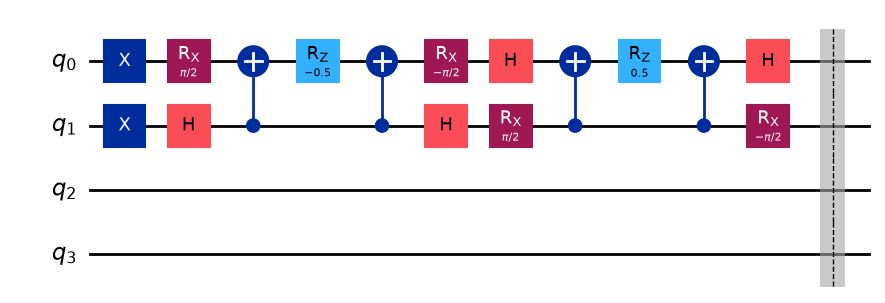

In [10]:
from qiskit import QuantumCircuit
def get_circuit(operators):

    # Build the ansatz
    qc = QuantumCircuit(4)

    # reference
    qc.x(0)
    qc.x(1)

    for f_op in operators:
        qubit_op = jordan_wigner(f_op)

        # print(op)
        for pauli_string, coef in qubit_op.terms.items():

            for qubit, pauli in pauli_string:
                if pauli == 'X':
                    qc.h(qubit)
                elif pauli == 'Y':
                    qc.rx(np.pi / 2, [qubit])

            for qubit, pauli in pauli_string[1:]:
                qc.cx(qubit, pauli_string[0][0])

            if len(pauli_string) > 0:
                qc.rz(coef.imag, pauli_string[0][0])

            for qubit, pauli in pauli_string[1:]:
                qc.cx(qubit, pauli_string[0][0])

            for qubit, pauli in pauli_string:
                if pauli == 'X':
                    qc.h(qubit)
                elif pauli == 'Y':
                    qc.rx(-np.pi / 2, [qubit])

        qc.barrier()

    #qc.draw('mpl')
    return qc

get_circuit(pool[:1]).draw('mpl')

## Choosing the operators

For a candidate generator $\tau_i$, ADAPT-VQE uses the energy gradient at zero coefficient,

$$g_i=\left.\frac{\partial E}{\partial\theta_i}\right|_{\theta_i=0}=\langle\psi|[H,\tau_i]|\psi\rangle. $$

The commutator is measured term by term. The operator with the largest absolute gradient is appended to the ansatz, and the parameters of all selected operators are then optimized together.

In [11]:
from qiskit.primitives import StatevectorSampler

def cost_function(operators, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = get_circuit(operators)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [12]:
from openfermion import jordan_wigner
H_qubit = jordan_wigner(hamiltonian)

In [13]:
for op in pool:
    qubit_op = jordan_wigner(op)
    commutator = qubit_op * H_qubit - H_qubit * qubit_op
    cost = abs(cost_function([], commutator))
    print('{:.5f} {:2s}'.format(cost, str(op).split('\n')[0]))


0.00056 1.0 [0^ 1] +
0.00000 0 
0.00005 -1.0 [1^ 2] +
0.00198 -1.0 [1^ 3] +
0.00127 1.0 [0^ 2] +
0.00273 1.0 [1^ 2] +
0.00000 0 
0.00006 -1.0 [2^ 3] +
0.00037 1.0 [1^ 0^ 2 1] +
0.00004 -1.0 [1^ 2^ 0 2] +
0.00000 -1.0 [1^ 2^ 0 3] +
0.00000 -1.0 [1^ 2^ 1 2] +
0.00025 -1.0 [1^ 2^ 1 3] +
0.00193 -1.0 [1^ 2^ 2 3] +


In [14]:
from scipy.optimize import minimize

def combine(parameters, operators):
    return [c * op for c, op in zip(parameters, operators)]

operators = []
parameters = []
for step in range(3):

    i_max = 0
    grad_max = 0
    cost_vector = []

    print('gradients')
    for i, op in enumerate(pool):
        qubit_op = jordan_wigner(op)
        commutator = qubit_op * H_qubit - H_qubit * qubit_op
        cost = abs(cost_function(combine(parameters, operators), commutator))
        cost_vector.append(cost)
        print('{:.5f} {}'.format(cost, str(op).replace('\n', ' ')))

        if cost > grad_max:
            grad_max = cost
            i_max = i

    # convergence criteria
    grad_norm = np.linalg.norm(cost_vector)
    print('gradient norm', grad_norm)
    if grad_norm < 1e-1:
        print('converged')
        break

    operators.append(pool[i_max])
    print('selected: ', pool[i_max])

    def cost_adapt(trial_params, H_qubit):
        return cost_function(combine(trial_params, operators), H_qubit)

    # Initial parameters
    parameters.append(0)


    # Optimization
    print('minimization')
    result = minimize(
        cost_adapt,
        parameters,
        args=(H_qubit),
        method="COBYLA",
        options={"maxiter": 200,
                 "disp": True,
                 "rhobeg": 0.5,
                 "tol": 1e-4,
        },
    )

    print("Optimal parameters:", result.x)
    print("Minimum energy:", result.fun)

    parameters = result.x.tolist()



gradients
0.00048 1.0 [0^ 1] + -1.0 [1^ 0]
0.00000 0
0.00153 -1.0 [1^ 2] + 1.0 [2^ 1]
0.00019 -1.0 [1^ 3] + 1.0 [3^ 1]
0.00120 1.0 [0^ 2] + -1.0 [2^ 0]
0.00080 1.0 [1^ 2] + -1.0 [2^ 1]
0.00000 0
0.00022 -1.0 [2^ 3] + 1.0 [3^ 2]
0.00017 1.0 [1^ 0^ 2 1] + -1.0 [1^ 2^ 0 1]
0.00007 -1.0 [1^ 2^ 0 2] + 1.0 [2^ 0^ 2 1]
0.00000 -1.0 [1^ 2^ 0 3] + 1.0 [3^ 0^ 2 1]
0.00000 -1.0 [1^ 2^ 1 2] + 1.0 [2^ 1^ 2 1]
0.00005 -1.0 [1^ 2^ 1 3] + 1.0 [3^ 1^ 2 1]
0.00036 -1.0 [1^ 2^ 2 3] + 1.0 [3^ 2^ 2 1]
gradient norm 0.002208714255023918
converged


In [15]:
from openfermion import FermionOperator, jordan_wigner


def sz_operator(n_spatial_orbitals):

    Sz = FermionOperator()

    for p in range(n_spatial_orbitals):

        alpha = 2 * p
        beta = 2 * p + 1

        Sz += 0.5 * FermionOperator(f'{alpha}^ {alpha}')
        Sz -= 0.5 * FermionOperator(f'{beta}^ {beta}')

    return jordan_wigner(Sz)



def s2_operator(n_spatial_orbitals):

    # Build S+ and S- in second quantization
    S_plus = FermionOperator()
    S_minus = FermionOperator()

    for p in range(n_spatial_orbitals):

        alpha = 2 * p
        beta = 2 * p + 1

        S_plus += FermionOperator(f'{alpha}^ {beta}')
        S_minus += FermionOperator(f'{beta}^ {alpha}')

    # Jordan-Wigner transformation
    S_plus = jordan_wigner(S_plus)
    S_minus = jordan_wigner(S_minus)

    # Sz
    Sz = sz_operator(n_spatial_orbitals)

    # S^2 = Sz^2 + 1/2 (S+ S- + S- S+)
    S2 = Sz * Sz + 0.5 * (S_plus * S_minus + S_minus * S_plus)

    return S2

In [16]:
print('Sz: {:.5f}'.format(cost_function(combine(parameters, operators), H_qubit=sz_operator(2))))
print('S2: {:.5f}'.format(cost_function(combine(parameters, operators), H_qubit=s2_operator(2))))

Sz: 0.00000
S2: -0.00019


## Symmetry diagnostics and extensions

After optimization, the notebook measures $S_z$ and $S^2$. These observables test whether the prepared state has the intended spin quantum numbers. The final prompts invite applying the same adaptive procedure separately to singlet and triplet sectors by changing the initial state and operator pool.

Proposed exercises:
----------------------
- Change the algorithm (pool initial state) to optimize the first triplet
- Modify the ansatz to compute the following states:
    - Singlet (ground state)
    - Triplet (ms=0)
    - Triplet (ms=1/-1)